# Class 16: Writing functions

In this notebook we continue with the fundamentals of Python, namely writing our own functions. This material will be useful for analyzing data, and more generally for any programming you do in the future.


In [ ]:
import YData

# YData.download.download_class_code(16)         # get class code
# YData.download.download_class_code(16, True)   # get the code with the answers

In [ ]:
import numpy as np
np.random.seed(123)   # fixed seed so results are reproducible
import matplotlib.pyplot as plt
import random

## 1. Functions!

We have already used many functions in this class that are built into Python or are imported from different modules/packages. 

Let's now write some new functions outselves! 


In [ ]:
# Write a function that doubles a value
def double(x):
    return x * 2

In [ ]:
# Try the function out 1
double(7)

14

In [ ]:
# Try the function out 2
double(15/3)

10.0

In [ ]:
# Try the function out 3
my_number = 12
double(my_number)

24

In [ ]:
# Try the function out 4
double(my_number / 8)

3.0

In [ ]:
# Will this work?
double(np.array([3, 4, 5]))

array([ 6,  8, 10])

In [ ]:
# Will this work? 
double('data')

'datadata'

In [ ]:
# What about this? 
double(True)

2

In [ ]:
# "local scope"
# x

In [ ]:
# Let's set x to 17 
x = 17

In [ ]:
# Double 2
double(2)

4

In [ ]:
# Did x change?
x

17

In [ ]:
# What if we double x? 
double(x)

34

In [ ]:
# Did x change?
x

17

### Function extras: docstrings

When writing functions that will be used by other people (or your future self) it is important to write some documentation describing how your function works. In Python, this type of documentation is called a "docstring". The text in a docstring is in triple quotes which allows for multi-line comments.

There are a number of [convensions](https://peps.python.org/pep-0257/) surrounding on how to write a docstring, including: 

- The doc string line should begin with a capital letter and end with a period.
- The first line should be a short description.
- If there are more lines in the documentation string, the second line should be blank, visually separating the summary from the rest of the description.
- The following lines should be one or more paragraphs describing the object’s calling conventions, its side effects, etc.


In [ ]:
def double(x):
    """Take a number and doubles it.
    
    Parameters:
    x (int): A number that should be doubled
    
    Returns:
    int: The numbers that is doubled
    
    """
    return x * 2

In [ ]:
# View the docstring
? double

Signature:  double(x)
Docstring:
Take a number and doubles it.

Parameters:
x (int): A number that should be doubled

Returns:
int: The numbers that is doubled
File:      /var/folders/_5/xc897jbx4p365zpzqq1xwttx8qnj14/T/ipykernel_976/4122166559.py
Type:      function

### Multiple arguments and default values

We can also write functions that take multiple arguments and we can set particular arguments to have default values that are used if no value for an argument is given. 

Let's explore this...



In [ ]:
# Define powerit function 
def powerit(x, pow):
    return x**pow

In [ ]:
# Use the function 
powerit(2, 3)

8

In [ ]:
# Try the function with a single argument
#powerit(2)

In [ ]:
# Set a default argument value

def powerit(x, pow = 3):
    return x**pow

In [ ]:
# Try the new function with a single argument
powerit(2)

8

In [ ]:
# Try the function with two arguments
powerit(2, 5)

32

![higher powers](powers.jpg)

### Multiple return values 

We can also write funciton that can return multiple values. We can do this by returning a tuple. 

Recall, tuples are a basic data structure in Python that is like a list. However, unlike lists, elements in tuples are "immutable" meaning that once we create a tuple, we can not modify the values in the tuple.

We create tuples by using values in parentheses separated by commas:

`my_tuple = (10, 20, 30)`

Let's explore tuples now... 

In [ ]:
# Recall tuples
my_tuple = (10, 20, 30)

my_tuple

(10, 20, 30)

In [ ]:
# We can access elements of the tuple using square brackets (the same as lists)
my_tuple[1]

20

In [ ]:
# Unlike a list, we can't reassign values in a tuple 
#my_tuple[1] = 50

In [ ]:
# We extract values from tuples into regular names using "tuple unpacking"

val1, val2, val3 = my_tuple


val3


30

Let's create a function `power23(x)` that returns a number squared and a number cubed. 

In [ ]:
# Create a function that returns a value squared and cubed

def sqr_and_cube(x):
    
    return (x**2, x**3)

In [ ]:
sqr_and_cube(2)

(4, 8)

In [ ]:
# We can use "tuple unpacking" to assign both outputs to different names
squared, cubed = sqr_and_cube(2)  

print(squared)
print(cubed)


4
8


### Passing functions as input arguments

We can also pass functions as input arguments to other functions. Let's explore this...

In [ ]:
def compute_on_my_array(stat_function):
    
    my_array = np.array([21, 44, 54, 23, 25, 32])
    
    calculated_val = stat_function(my_array)
    
    return calculated_val

In [ ]:
# Apply the np.mean function to my_array
compute_on_my_array(np.mean)

np.float64(33.166666666666664)

In [ ]:
# Apply the np.sum function to my_array
compute_on_my_array(np.sum)

np.int64(199)

In [ ]:
# Apply power23 to my_array
compute_on_my_array(sqr_and_cube)

(array([ 441, 1936, 2916,  529,  625, 1024]),
 array([  9261,  85184, 157464,  12167,  15625,  32768]))

## 2. Additional practice writing functions

As additional pracice, let's write a function that will mimic flipping coins. This function will be useful when we start talking about statistical inference. 

In particular, let's write a function called `flip_coins(n, prob)` which will simulate flipping a coin `n` times where:
- `n` is the number of times we have flipped the coin
- `prob` is the probability that each coin flip will return "head"

The function should return the number of "heads" that occurred from flipping the coin `n` times; i.e., it should return a number between 0, which means no heads occurred, and `n` which means a "head" occurred on every flip. 

When writing functions, it is often useful to write the bulk of the code outside of a function and then turn in into a function by wrapping your code in a `def` statement. Let's go through a few steps of writing this function now. 


#### Step 1: Generating random numbers between 0 and 1

We can use the numpy function `np.random.rand(n)` to generate `n` random numbers. Please create a name called `n` and set it equal to 500 to simulate 500 random coin flips. Then use the name `n`, along with the `np.random.rand(n)` to generate 500 random numbers between 0 and 1. Save these random numbers to the name `rand_nums`. 

Finally, to see what these numbers look like, visualize `rand_nums` using a histogram. 


[0.69646919 0.28613933 0.22685145 0.55131477 0.71946897 0.42310646
 0.9807642  0.68482974 0.4809319  0.39211752]


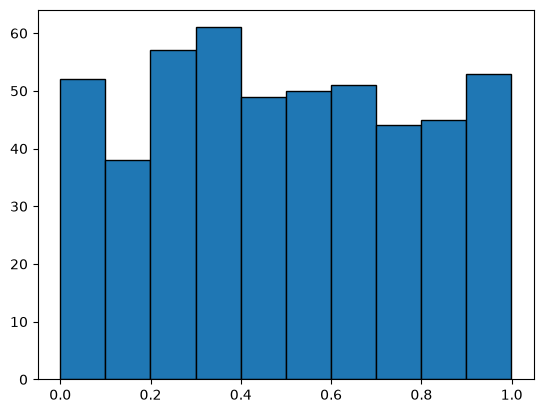

In [ ]:
# Use np.random.rand() to generate n = 500 random numbers between 0 and 1, and visualize them as a histogram. 

n = 500

rand_nums = np.random.rand(n)

print(rand_nums[0:10])

plt.hist(rand_nums, edgecolor = "k");


#### Step 2: Count the number of "heads"

Next create a name called `prob` which has the probability that a coin flip is a "head". Let's set `prob` to be equal to .5 to simulate flipping a fair coin. Then see how many of the `rand_nums` are less than the `prob` value to see how many of your coin flips were "head"; i.e., use `np.sum()` to count how many of your coin flips were heads. 



In [ ]:
# Set prob to .5 and count how many values are greater than prob

prob = .5

np.sum(rand_nums <= prob)

np.int64(257)

#### Step 3: Creating the function flip_coins(n, prob)

Now write the function `flip_coins(n, prob)` by taking the code you wrote in the previous two steps and turning it into a function. 

Then try out the function a few times and see how the number of "heads" you get varies from simulation to simulation, and also experiment with different values for the arguments `n` and `prob`. 


In [ ]:
# Create a function flip_coins(n, prob) that generates n random numbers and returns how many are less than prob

def flip_coins(n, prob):
    rand_nums = np.random.rand(n)
    num_heads = np.sum(rand_nums <= prob)
    return num_heads
    

flip_coins(500, .5)

np.int64(251)

#### Step 4: Adding an additional argument to the function 

Let's add an additional parameter to the `flip_coins` function called `return_prop` which has a default value of `False`; i.e., the function should now be `flip_coins(n, prob, return_prop = False)`. If the `return_prop` is set to `True` that it should return the proportion of coin flips that were heads rather than the number of coin flips that were heads. 

Hint: Adding a conditional statement to your function could be useful. 



In [ ]:
# Add an argument return_prop that when set to True will return the proporton of coin flips that were heads (rather than the number of heads)

def flip_coins(n, prob, return_prop = False):
    
    rand_nums = np.random.rand(n)
    num_heads = np.sum(rand_nums <= prob)
    
    if return_prop:
        return num_heads/n
    else:
        return num_heads
    
    
print(flip_coins(500, .5))
print(flip_coins(500, .5, True))


257
0.482
